
# Read pridb


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import vallenae as vae

HERE = Path(__file__).parent if "__file__" in locals() else Path.cwd()
PRIDB = "CAI-spec1.pridb"

## Open pridb



In [85]:
pridb = vae.io.PriDatabase(PRIDB)

print("Tables in database: ", pridb.tables())
print("Number of rows in data table (ae_data): ", pridb.rows())
print("Set of all channels: ", pridb.channel()) 
print("all columns: ", pridb.columns())

Tables in database:  {'ae_globalinfo', 'ae_params', 'ae_data', 'acq_setup', 'ae_fieldinfo', 'ae_markers', 'data_integrity'}
Number of rows in data table (ae_data):  65646
Set of all channels:  {1, 2}
all columns:  ('SetID', 'SetType', 'Time', 'Chan', 'Status', 'ParamID', 'Thr', 'Amp', 'RiseT', 'Dur', 'Eny', 'SS', 'RMS', 'Counts', 'TRAI', 'PCTD', 'PCTA', 'PA0', 'PA1')


## Read hits to Pandas DataFrame



In [87]:
df = pridb.read()
df

Status: 100%|██████████| 24/24 [00:00<00:00, 2395.89it/s]


,time,set_type,channel,param_id,amplitude,duration,energy,rms,status,threshold,rise_time,signal_strength,counts,trai,pctd,pcta,pa0,pa1
set_id,,,,,,,,,,,,,,,,,,
1,0.000000,6,<NA>,<NA>,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN
2,0.000000,4,<NA>,<NA>,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN
3,0.000000,5,<NA>,<NA>,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN
4,0.000000,4,<NA>,<NA>,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN
5,0.000000,1,<NA>,1,NaN,NaN,NaN,NaN,12,NaN,NaN,NaN,<NA>,<NA>,0,0,-4.0625,-5.9375
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65642,126.568230,2,2,3,0.000174,1.094000e-04,13.767104,0.00002,0,0.0001,4.700000e-06,4.573795,4,0,<NA>,<NA>,NaN,NaN
65643,126.568558,2,2,3,0.000143,1.210000e-04,11.822065,0.00002,0,0.0001,1.520000e-05,4.468455,3,0,<NA>,<NA>,NaN,NaN
65644,126.568910,2,2,3,0.000125,7.000000e-07,7.804721,0.00002,0,0.0001,6.000000e-07,2.939492,1,27120,<NA>,<NA>,NaN,NaN


In [183]:
df.isnull().sum()

time                   0
set_type               0
channel             7017
param_id               5
amplitude           7041
duration            7041
energy              7017
rms                 7017
status                 5
threshold           7017
rise_time           7041
signal_strength     7017
counts              7041
trai                7041
pctd               58634
pcta               58634
pa0                58634
pa1                58634
dtype: int64

In [187]:
df["set_type"].value_counts()

set_type
2    58605
1     7012
3       24
4        3
6        1
5        1
Name: count, dtype: int64

In [70]:
df_hits = pridb.read_hits()
df_hits

Hits: 100%|██████████| 58605/58605 [00:00<00:00, 62951.44it/s]


,time,channel,param_id,amplitude,duration,energy,rms,status,threshold,rise_time,signal_strength,counts,trai
set_id,,,,,,,,,,,,,
6,0.000005,2,3,0.001000,1.048530e-01,48274.158435,0.00000,1,0.0001,9.008070e-02,5200.658866,13625,1
8,0.104858,2,3,0.001005,1.048576e-01,47730.280794,0.00000,257,0.0001,8.539480e-02,5175.026371,13808,0
10,0.209715,2,3,0.001066,1.048576e-01,48576.249073,0.00000,257,0.0001,8.037030e-02,5186.968230,13529,0
12,0.314573,2,3,0.001066,1.048576e-01,48924.451900,0.00000,257,0.0001,1.727100e-03,5200.751420,13655,0
14,0.419430,2,3,0.001066,1.048576e-01,48933.926459,0.00000,257,0.0001,1.727100e-03,5215.046091,13788,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65640,126.567557,2,3,0.000128,1.126000e-04,12.279683,0.00002,0,0.0001,1.000000e-07,4.543046,3,0
65641,126.567896,2,3,0.000122,1.051000e-04,12.644146,0.00002,0,0.0001,1.000000e-07,4.540305,5,27119
65642,126.568230,2,3,0.000174,1.094000e-04,13.767104,0.00002,0,0.0001,4.700000e-06,4.573795,4,0


In [171]:
df_hits.isnull().sum()

time               0
channel            0
param_id           0
amplitude          0
duration           0
energy             0
rms                0
status             0
threshold          0
rise_time          0
signal_strength    0
counts             0
trai               0
dtype: int64

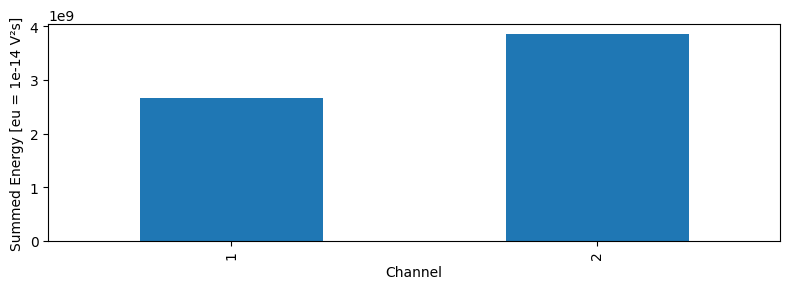

In [72]:
# Query Pandas DataFrame

ax = df_hits.groupby("channel").sum()["energy"].plot.bar(figsize=(8, 3))
ax.set_xlabel("Channel")
ax.set_ylabel("Summed Energy [eu = 1e-14 V²s]")
plt.tight_layout()
plt.show()

## Read markers



In [75]:
df_markers = pridb.read_markers()
df_markers

Marker: 100%|██████████| 5/5 [00:00<00:00, 3146.99it/s]


,time,set_type,data,number
set_id,,,,
1,0.00,6,,1
2,0.00,4,14:04 Resume,1
3,0.00,5,2021-11-13 14:04:29,<NA>
4,0.00,4,TimeZone: +01:00 (W. Europe Standard Time),2
65646,126.62,4,14:06 Suspend,3


## Read parametric data



In [78]:
df_parametric = pridb.read_parametric()
df_parametric

Parametric: 100%|██████████| 7012/7012 [00:00<00:00, 62140.99it/s]


,time,param_id,status,pctd,pcta,pa0,pa1
set_id,,,,,,,
5,0.00,1,12,0,0,-4.0625,-5.9375
7,0.10,1,13,0,0,-4.6875,-5.6250
9,0.20,1,13,0,0,-4.6875,-5.9375
11,0.31,1,12,0,0,0.6250,-1.2500
13,0.41,1,12,0,0,1.5625,-0.6250
...,...,...,...,...,...,...,...
65553,126.53,1,13,0,0,-2559.0625,-336.2500
65577,126.54,1,12,0,0,-2554.3750,-332.5000
65600,126.55,1,13,0,0,-2558.1250,-337.5000


## Read Status Data

In [81]:
df_status = pridb.read_status()
df_status

Status: 100%|██████████| 24/24 [00:00<00:00, 2057.80it/s]


,time,channel,param_id,energy,rms,status,threshold,signal_strength
set_id,,,,,,,,
207,10.000794,1,2,4.038421e+04,0.000006,0,0.0001,4.922633e+04
208,10.000794,2,3,4.550732e+06,0.000000,0,0.0001,4.920814e+05
418,20.001587,1,2,4.676157e+04,0.000008,0,0.0001,5.293030e+04
419,20.001587,2,3,4.588221e+06,0.000000,0,0.0001,4.946027e+05
644,30.002381,1,2,9.903067e+04,0.000011,0,0.0001,7.864353e+04
645,30.002381,2,3,4.787592e+06,0.000000,0,0.0001,5.092328e+05
1221,40.003174,1,2,1.593480e+05,0.000014,0,0.0001,9.830225e+04
1222,40.003174,2,3,3.865690e+06,0.000000,0,0.0001,4.742611e+05
2075,50.003968,1,2,1.985785e+05,0.000014,0,0.0001,1.090021e+05


In [117]:
import vallenae.io as vio

tradb = vio.TraDatabase("CAI-spec1.tradb")
tra = tradb.read()
tra 

Tra: 100%|██████████| 27120/27120 [00:06<00:00, 4267.45it/s]


,time,channel,param_id,pretrigger,threshold,samplerate,samples,data,status,raw
trai,,,,,,,,,,
1,0.000005,2,3,9,0.0001,2000000,2048,"[-1.5222642e-05, -1.2178114e-05, 1.8267172e-05...",32768,False
2,16.168292,1,2,100,0.0001,2000000,2048,"[9.133586e-06, 3.0445285e-06, 0.0, -6.089057e-...",32768,False
3,16.693153,1,2,100,0.0001,2000000,2048,"[-6.089057e-06, -1.2178114e-05, -3.0445285e-06...",32768,False
4,16.765947,1,2,100,0.0001,2000000,2048,"[-3.957887e-05, 6.089057e-06, 1.8267172e-05, 3...",32768,False
5,18.385182,1,2,100,0.0001,2000000,2048,"[9.133586e-06, 1.2178114e-05, 9.133586e-06, 1....",32768,False
...,...,...,...,...,...,...,...,...,...,...
27116,126.564181,2,3,100,0.0001,2000000,2048,"[-3.0445285e-06, -9.133586e-06, 3.3489814e-05,...",32768,False
27117,126.565648,2,3,100,0.0001,2000000,2048,"[-9.133586e-06, 3.3489814e-05, -4.26234e-05, -...",32768,False
27118,126.566688,2,3,100,0.0001,2000000,2048,"[-3.0445284e-05, -3.0445285e-06, -3.0445285e-0...",32768,False


In [129]:
print(tradb.channel())
print(tradb.columns())
print(tradb.tables())
print(tradb.fieldinfo())

{1, 2}
('SetID', 'Time', 'TRAI', 'Status', 'ParamID', 'Chan', 'Pretrigger', 'Thr', 'SampleRate', 'Samples', 'DataFormat', 'Data')
{'tr_params', 'tr_globalinfo', 'tr_fieldinfo', 'tr_data'}
{'Time': {'Unit': '[s]', 'Parameter': None}, 'Thr': {'Unit': '[µV]', 'Parameter': 'ADC_µV'}, 'SampleRate': {'Unit': '[Hz]', 'Parameter': None}, 'Data': {'Unit': None, 'Parameter': 'TR_mV'}}


In [143]:
tra[['data']]

,data
trai,
1,"[-1.5222642e-05, -1.2178114e-05, 1.8267172e-05..."
2,"[9.133586e-06, 3.0445285e-06, 0.0, -6.089057e-..."
3,"[-6.089057e-06, -1.2178114e-05, -3.0445285e-06..."
4,"[-3.957887e-05, 6.089057e-06, 1.8267172e-05, 3..."
5,"[9.133586e-06, 1.2178114e-05, 9.133586e-06, 1...."
...,...
27116,"[-3.0445285e-06, -9.133586e-06, 3.3489814e-05,..."
27117,"[-9.133586e-06, 3.3489814e-05, -4.26234e-05, -..."
27118,"[-3.0445284e-05, -3.0445285e-06, -3.0445285e-0..."


In [165]:
print(tradb.read_wave(trai = 3))

(array([-6.0890570e-06, -1.2178114e-05, -3.0445285e-06, ...,
        0.0000000e+00,  0.0000000e+00, -3.0445285e-06],
      shape=(2048,), dtype=float32), array([-5.000e-05, -4.950e-05, -4.900e-05, ...,  9.725e-04,  9.730e-04,
        9.735e-04], shape=(2048,)))


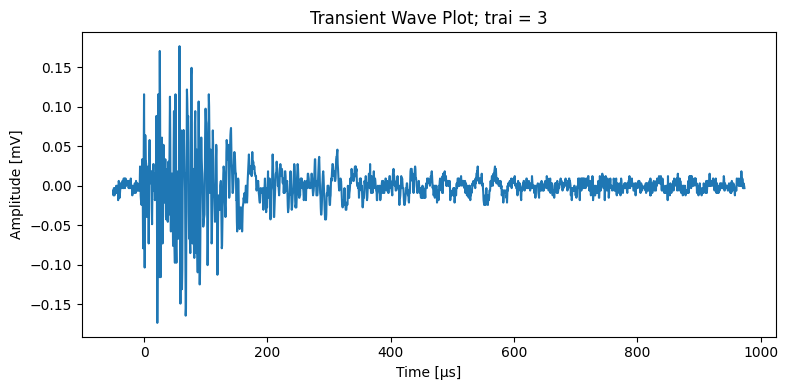

In [167]:
HERE = Path(__file__).parent if "__file__" in locals() else Path.cwd()
TRADB = "CAI-spec1.tradb"  # uncompressed
TRAI = 3  # just an example, no magic here

def main():
    # Read waveform from tradb
    with vae.io.TraDatabase(TRADB) as tradb:
        y, t = tradb.read_wave(TRAI)

    y *= 1e3  # in mV
    t *= 1e6  # for µs

    # Plot waveforms
    plt.figure(figsize=(8, 4), tight_layout=True)
    plt.plot(t, y)
    plt.xlabel("Time [µs]")
    plt.ylabel("Amplitude [mV]")
    plt.title(f"Transient Wave Plot; trai = {TRAI}")
    plt.show()


if __name__ == "__main__":
    main()